In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input,
    GlobalAveragePooling2D,
    Dense,
    Dropout
)
from tensorflow.keras.utils import image_dataset_from_directory

In [2]:
import os
import tarfile

tar_path = r"caltech101\caltech-101\101_ObjectCategories.tar.gz"

extract_path = r"caltech101\caltech-101"

with tarfile.open(tar_path, 'r:gz') as tar:
    tar.extractall(path=extract_path)

print("Object categories extracted successfully!")

Object categories extracted successfully!


In [3]:
class_names = [
    'airplanes',
    'Faces',
    'Motorbikes',
    'Leopards',
    'watch'
]

dataset_path = r"caltech101\caltech-101\101_ObjectCategories"

for category in class_names:
    category_path = os.path.join(dataset_path, category)

    print(category, ":", os.path.isdir(category_path))

airplanes : True
Faces : True
Motorbikes : True
Leopards : True
watch : True


In [4]:
import tensorflow as tf
import os

IMG_SIZE = (224, 224)
BATCH_SIZE = 8

dataset_path = r"caltech101\caltech-101\101_ObjectCategories"

class_names = [
    'airplanes',
    'Faces',
    'Motorbikes',
    'Leopards',
    'watch'
]

train_datasets = []
test_datasets = []

for label, category in enumerate(class_names):

    category_path = os.path.join(dataset_path, category)

    train_ds = tf.keras.utils.image_dataset_from_directory(
        dataset_path,
        image_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        label_mode='categorical',
        validation_split=0.2,
        subset='training',
        seed=42,
        class_names=[category]
    )

Found 800 files belonging to 1 classes.
Using 640 files for training.
Found 435 files belonging to 1 classes.
Using 348 files for training.
Found 798 files belonging to 1 classes.
Using 639 files for training.
Found 200 files belonging to 1 classes.
Using 160 files for training.
Found 239 files belonging to 1 classes.
Using 192 files for training.


In [5]:
import os
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split

dataset_path = r"caltech101\caltech-101\101_ObjectCategories"

class_names = [
    'airplanes',
    'Faces',
    'Motorbikes',
    'Leopards',
    'watch'
]

image_paths = []
labels = []

for label, category in enumerate(class_names):

    folder = os.path.join(dataset_path, category)

    for filename in os.listdir(folder):

        if filename.lower().endswith(('.jpg', '.jpeg', '.png')):
            image_paths.append(os.path.join(folder, filename))
            labels.append(label)

image_paths = np.array(image_paths)
labels = np.array(labels)

train_paths, test_paths, y_train, y_test = train_test_split(
    image_paths,
    labels,
    test_size=0.2,
    random_state=42,
    stratify=labels
)

print("Training images:", len(train_paths))
print("Testing images:", len(test_paths))

Training images: 1977
Testing images: 495


In [6]:
def load_image(path, label):

    image = tf.io.read_file(path)

    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(image, (224, 224))

    label = tf.one_hot(label, depth=5)

    return image, label


train_ds = tf.data.Dataset.from_tensor_slices(
    (train_paths, y_train)
)

train_ds = (
    train_ds
    .shuffle(1000)
    .map(load_image, num_parallel_calls=1)
    .batch(8)
    .prefetch(1)
)

test_ds = tf.data.Dataset.from_tensor_slices(
    (test_paths, y_test)
)

test_ds = (
    test_ds
    .map(load_image, num_parallel_calls=1)
    .batch(8)
    .prefetch(1)
)

print("Training and testing datasets created successfully!")

Training and testing datasets created successfully!


In [7]:
from tensorflow.keras.applications.vgg16 import preprocess_input

train_ds = train_ds.map(
    lambda x, y: (preprocess_input(x), y)
)

test_ds = test_ds.map(
    lambda x, y: (preprocess_input(x), y)
)

In [8]:
from tensorflow.keras.applications import VGG16

base_model = VGG16(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze lower convolutional blocks
for layer in base_model.layers:
    if layer.name.startswith(('block1_', 'block2_', 'block3_')):
        layer.trainable = False
    else:
        layer.trainable = True

print("VGG16 loaded successfully!")

VGG16 loaded successfully!


In [9]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, GlobalAveragePooling2D, Dense, Dropout
)

inputs = Input(shape=(224, 224, 3))

x = base_model(inputs)

x = GlobalAveragePooling2D()(x)

x = Dense(256, activation='relu')(x)

x = Dense(128, activation='relu')(x)

x = Dropout(0.5)(x)

outputs = Dense(5, activation='softmax')(x)

model = Model(inputs, outputs)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)           │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ vgg16 (Functional)                   │ (None, 7, 7, 512)           │      14,714,688 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 512)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 256)                 │         131,328 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 5)                   │             645 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 14,879,557 (56.76 MB)

 Trainable params: 13,144,069 (50.14 MB)

 Non-trainable params: 1,735,488 (6.62 MB)

In [10]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [11]:
history = model.fit(
    train_ds,
    epochs=5,
    validation_data=test_ds
)

Epoch 1/5


C:\Users\saniya maner\miniconda3\envs\tensorflow_env\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


248/248 ━━━━━━━━━━━━━━━━━━━━ 406s 2s/step - accuracy: 0.8063 - loss: 0.6606 - val_accuracy: 0.9899 - val_loss: 0.0285
Epoch 2/5
248/248 ━━━━━━━━━━━━━━━━━━━━ 2533s 10s/step - accuracy: 0.9782 - loss: 0.0693 - val_accuracy: 0.9960 - val_loss: 0.0068
Epoch 3/5
248/248 ━━━━━━━━━━━━━━━━━━━━ 369s 1s/step - accuracy: 0.9924 - loss: 0.0259 - val_accuracy: 1.0000 - val_loss: 0.0016
Epoch 4/5
248/248 ━━━━━━━━━━━━━━━━━━━━ 371s 1s/step - accuracy: 0.9960 - loss: 0.0084 - val_accuracy: 1.0000 - val_loss: 0.0011
Epoch 5/5
248/248 ━━━━━━━━━━━━━━━━━━━━ 382s 2s/step - accuracy: 0.9965 - loss: 0.0118 - val_accuracy: 1.0000 - val_loss: 0.0013


In [12]:
test_loss, test_accuracy = model.evaluate(test_ds)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

62/62 ━━━━━━━━━━━━━━━━━━━━ 43s 693ms/step - accuracy: 1.0000 - loss: 0.0013
Test Loss: 0.001284287660382688
Test Accuracy: 100.0 %


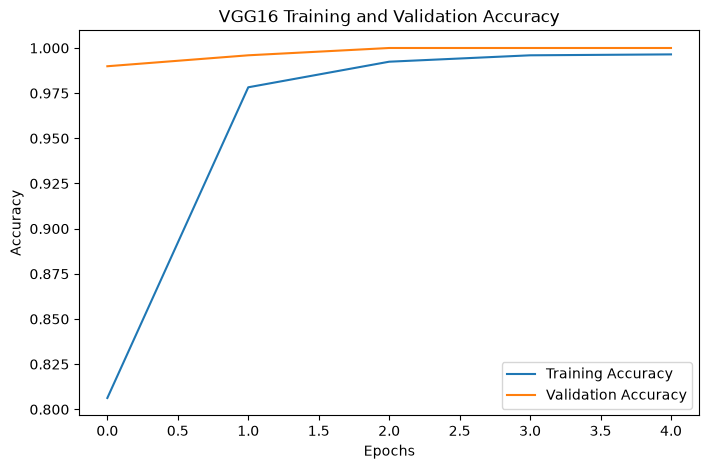

In [13]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('VGG16 Training and Validation Accuracy')

plt.legend()
plt.show()

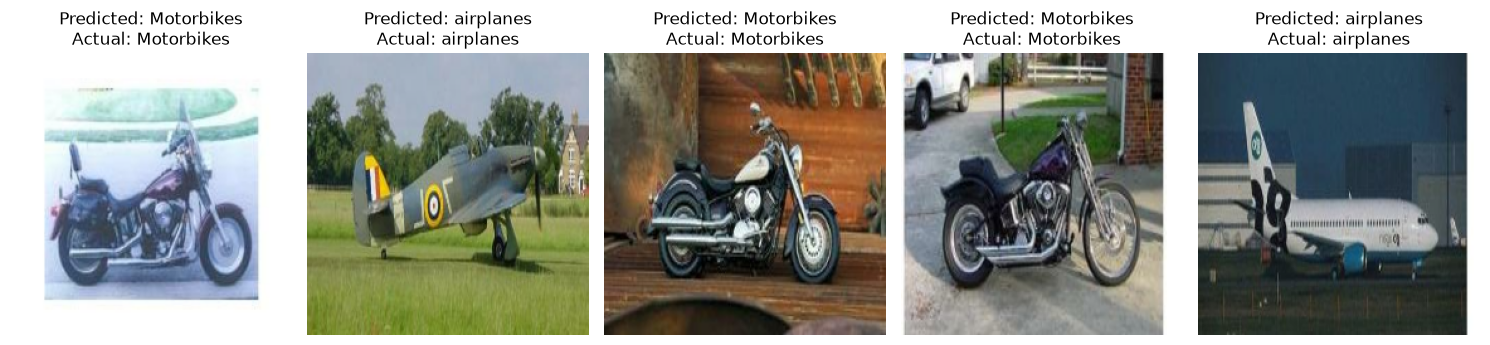

In [14]:
plt.figure(figsize=(15, 6))

for images, labels in test_ds.take(1):

    predictions = model.predict(images, verbose=0)

    predicted_labels = np.argmax(predictions, axis=1)
    actual_labels = np.argmax(labels.numpy(), axis=1)

    for i in range(min(5, len(images))):

        plt.subplot(1, 5, i + 1)

        img = images[i].numpy().copy()

        # Reverse VGG16 preprocessing
        img = img + [103.939, 116.779, 123.68]
        img = img[..., ::-1]
        img = np.clip(img, 0, 255).astype('uint8')

        plt.imshow(img)

        plt.title(
            "Predicted: " + class_names[predicted_labels[i]] +
            "\nActual: " + class_names[actual_labels[i]]
        )

        plt.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
# 27.Develop a Transfer Learning-based object classification model using
# VGG16 and the Caltech-101 dataset by designing a custom classification
# head. Perform the following steps:
# a. Load the Caltech-101 dataset and select any 5–10 object categories.
# b. Preprocess the images by resizing them to 224 × 224 pixels.
# c. Load the pre-trained VGG16 model with ImageNet weights and remove its
# original classification layers.
# d. Freeze the lower convolutional layers of VGG16 to retain the pre-trained
# features.
# e. Add a custom classifier containing GlobalAveragePooling2D, two Dense
# layers with ReLU activation, a Dropout layer and a Softmax output layer.
# f. Compile the model using Adam optimizer and categorical cross-entropy loss.
# g. Train the model using the selected Caltech-101 images.
# h. Display the training and validation accuracy and predict the object category
# for sample test images